# Exercise 2: Computer Vision — Image Blending Using OpenCV
**Government Officer Training – Advanced in Artificial Intelligence**

## Objective
Load two images with OpenCV, make their dimensions identical, blend them using `cv2.addWeighted()`, and display and save the original and blended images.

### Input files
Place `image1.jpg` and `image2.jpg` in the same folder as this notebook, or update `image1_path` and `image2_path` below. The sample images supplied with this exercise are simple generated illustrations.

In [3]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

## 1. Load the two input images
`cv2.imread()` reads the image files. OpenCV loads color images in BGR order; we convert them to RGB later for correct display with Matplotlib.

In [4]:
image1_path = 'image1.jpg'
image2_path = 'image2.jpg'

image1 = cv2.imread(image1_path)
image2 = cv2.imread(image2_path)

if image1 is None or image2 is None:
    raise FileNotFoundError('Could not load one or both images. Check the file paths.')

print('Image 1 dimensions:', image1.shape)
print('Image 2 dimensions:', image2.shape)

Image 1 dimensions: (420, 640, 3)
Image 2 dimensions: (420, 640, 3)


## 2. Resize images to matching dimensions
`cv2.addWeighted()` requires the two input arrays to have the same dimensions and number of channels. The second image is resized to match the first.

In [5]:
height, width = image1.shape[:2]
image2_resized = cv2.resize(image2, (width, height))

print('Image 1 size:', image1.shape)
print('Resized image 2 size:', image2_resized.shape)

Image 1 size: (420, 640, 3)
Resized image 2 size: (420, 640, 3)


## 3. Blend the images
`cv2.addWeighted()` calculates a weighted sum of the two images. Here, both images contribute equally (50% each), and the gamma value is set to zero.

In [6]:
alpha = 0.5  # Weight of image 1
beta = 0.5   # Weight of image 2
gamma = 0    # Scalar added to the weighted sum

blended = cv2.addWeighted(image1, alpha, image2_resized, beta, gamma)
print('Blending completed successfully.')

Blending completed successfully.


## 4. Display original images and blended result
Convert each image from BGR to RGB before displaying it with Matplotlib.

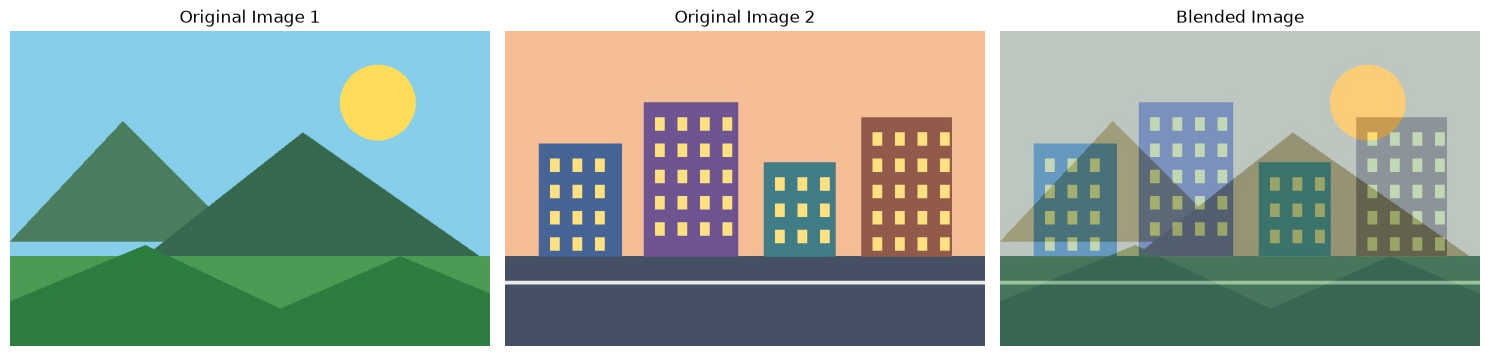

In [7]:
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2_resized, cv2.COLOR_BGR2RGB)
blended_rgb = cv2.cvtColor(blended, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image1_rgb)
plt.title('Original Image 1')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(image2_rgb)
plt.title('Original Image 2')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(blended_rgb)
plt.title('Blended Image')
plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Save the blended output image
The two original sample images are already supplied as input files. The following cell saves the composite image as `blended_image.jpg`.

In [8]:
output_path = 'blended_image.jpg'
if not cv2.imwrite(output_path, blended):
    raise IOError('Could not save the blended image.')
print(f'Blended image saved successfully: {output_path}')

Blended image saved successfully: blended_image.jpg


## 6. Conclusion
Two sample images were loaded using OpenCV and resized to matching dimensions. The images were combined using `cv2.addWeighted()` with equal weights. The original images and the blended result were displayed for verification, and the blended output was saved to disk.